# BT4012 Bitcoin Fraud Detection Task

## 0. Imports

In [1]:
from pathlib import Path
from time import perf_counter
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse as sp
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Print a short progress message while the notebook runs.
_START_TIME = perf_counter()

def tick(label):
    print(f"[{perf_counter() - _START_TIME:6.1f}s] {label}")

## 1. Load data

In [2]:
# The notebook is designed to be launched from the repository root.
# The CSV files are local inputs and are intentionally excluded from Git.
data_dir = Path.cwd()
required_files = ["train.csv", "test.csv", "txs_edgelist.csv"]
missing_files = [name for name in required_files if not (data_dir / name).is_file()]

if missing_files:
    raise FileNotFoundError(
        "Missing required data files: " + ", ".join(missing_files)
        + ". Place them in the repository root before running the notebook."
    )

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")
edges = pd.read_csv(data_dir / "txs_edgelist.csv")

raw_features = [c for c in test.columns if c.startswith("feat_")]

labeled = train[train["label"].isin([0, 1])].copy()
labeled["label"] = labeled["label"].astype(int)

dataset_summary = pd.DataFrame({
    "dataset": ["Train (all rows)", "Train (labelled)", "Test", "Transaction edges"],
    "rows": [len(train), len(labeled), len(test), len(edges)],
    "columns": [train.shape[1], labeled.shape[1], test.shape[1], edges.shape[1]],
})
display(dataset_summary)

,dataset,rows,columns
0,Train (all rows),141772,168
1,Train (labelled),31235,168
2,Test,15329,168
3,Transaction edges,234355,2


In [3]:
# Checking the time-based split.
time_summary = pd.DataFrame({
    "split": ["Labelled train", "Test"],
    "min_time_step": [labeled["time_step"].min(), test["time_step"].min()],
    "max_time_step": [labeled["time_step"].max(), test["time_step"].max()],
    "number_of_time_steps": [labeled["time_step"].nunique(), test["time_step"].nunique()],
})
display(time_summary)

overlap = sorted(set(train["time_step"]) & set(test["time_step"]))
if overlap:
    print("Warning: train and test share time steps:", overlap)
else:
    print("No time-step overlap: the test set represents a later period.")

,split,min_time_step,max_time_step,number_of_time_steps
0,Labelled train,1,35,35
1,Test,36,49,14


No time-step overlap: the test set represents a later period.


## 2. Data exploration

### 2.1 Data inputs and modelling boundary

| Input | Role | How it is used |
|---|---|---|
| `train.csv` | Historical transactions and labels | Used for profiling, training, and time-aware validation |
| `test.csv` | Future transactions to score | Used only for generating predictions; labels are unavailable |
| `txs_edgelist.csv` | Transaction-to-transaction links | Used to construct graph-based features |

### 2.2 Schema and data-quality checks

In [4]:
# Summarise the columns that define identity, time, the target, and model inputs.
id_columns = [c for c in ["index", "txId"] if c in train.columns]
schema_summary = pd.DataFrame({
    "field group": ["Identifiers", "Target", "Time", "Model features"],
    "columns": [
        ", ".join(id_columns) or "none found",
        "label" if "label" in train.columns else "not present",
        "time_step" if "time_step" in train.columns else "not present",
        f"{len(raw_features)} columns ({raw_features[0]} to {raw_features[-1]})" if raw_features else "none found",
    ],
})
display(schema_summary)

# Check missing values only on columns shared by train and test.
# The label is intentionally absent from test, so it is not treated as missing.
common_columns = sorted(set(train.columns) & set(test.columns))
missing_summary = pd.DataFrame({
    "train_missing": train[common_columns].isna().sum(),
    "test_missing": test[common_columns].isna().sum(),
})
missing_summary["maximum_missing"] = missing_summary.max(axis=1)
missing_summary = missing_summary[missing_summary["maximum_missing"] > 0].sort_values("maximum_missing", ascending=False)

if missing_summary.empty:
    print("No missing values found in train or test.")
else:
    display(missing_summary.head(15))


,field group,columns
0,Identifiers,txId
1,Target,label
2,Time,time_step
3,Model features,165 columns (feat_1 to feat_165)


No missing values found in train or test.


### 2.3 Label distribution and temporal behaviour

The positive-label rate is reported by time step because a changing rate can affect threshold selection and the reliability of random validation splits.

In [5]:
label_summary = (
    labeled["label"]
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .reset_index(name="rows")
)
label_summary["share"] = label_summary["rows"] / label_summary["rows"].sum()
display(label_summary.style.format({"share": "{:.2%}"}))

time_label_summary = (
    labeled.groupby("time_step")["label"]
    .agg(rows="size", positive_labels="sum", positive_rate="mean")
    .reset_index()
)
display(time_label_summary.head(10))


,label,rows,share
0,0,27591,88.33%
1,1,3644,11.67%


,time_step,rows,positive_labels,positive_rate
0,1,2147,17,0.007918
1,2,1117,18,0.016115
2,3,1279,11,0.008600
3,4,1440,30,0.020833
4,5,1882,8,0.004251
5,6,485,5,0.010309
6,7,1203,102,0.084788
7,8,1165,67,0.057511
8,9,778,248,0.318766
9,10,972,18,0.018519


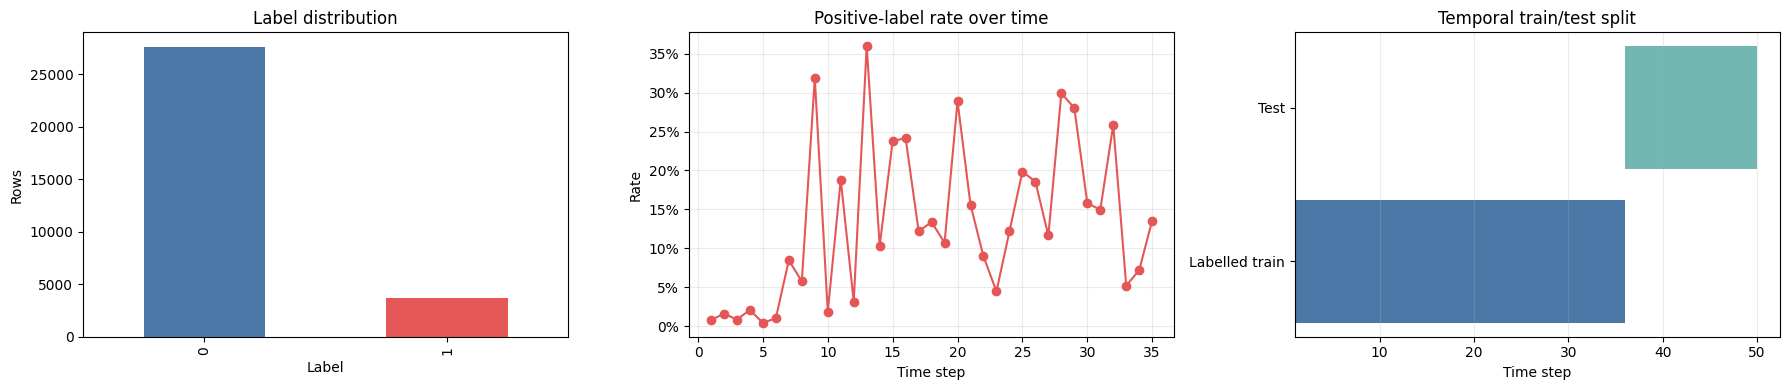

In [6]:
# Plots to summarise class balance, label drift, and the temporal split.
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

label_summary.plot.bar(
    x="label", y="rows", ax=axes[0], legend=False,
    color=["#4C78A8", "#E45756"]
)
axes[0].set_title("Label distribution")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Rows")

axes[1].plot(
    time_label_summary["time_step"],
    time_label_summary["positive_rate"],
    marker="o",
    color="#E45756",
)
axes[1].set_title("Positive-label rate over time")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Rate")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axes[1].grid(alpha=0.25)

split_labels = ["Labelled train", "Test"]
split_start = [labeled["time_step"].min(), test["time_step"].min()]
split_width = [
    labeled["time_step"].max() - labeled["time_step"].min() + 1,
    test["time_step"].max() - test["time_step"].min() + 1,
]
axes[2].barh(split_labels, split_width, left=split_start, color=["#4C78A8", "#72B7B2"])
axes[2].set_title("Temporal train/test split")
axes[2].set_xlabel("Time step")
axes[2].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 3. Data preprocessing

### 3.1 Feature Engineering 1: Remove redundant and highly correlated features

In [7]:
# Two features whose Spearman correlation is at least this are treated as near-copies.
CORR_THRESHOLD = 0.95

def greedy_correlation_prune(frame, columns, threshold=0.95, verbose=False):
    '''Keep one representative from each group of near-copies using a deterministic greedy order.'''
    # Replace infinities temporarily; median-filled values are used only for comparison.
    x = frame[columns].replace([np.inf, -np.inf], np.nan)
    filled = x.fillna(x.median(numeric_only=True))
    n_unique = filled.nunique(dropna=False)

    nonconstant = [c for c in columns if n_unique[c] > 1]                     # step 1a: drop constant columns
    constant_removed = len(columns) - len(nonconstant)
    duplicated = filled[nonconstant].T.duplicated(keep='first')               # step 1b: drop exact duplicate columns
    duplicate_removed = int(duplicated.sum())
    candidates = [c for c in nonconstant if c not in duplicated[duplicated].index]
   
    # Spearman correlation compares feature ranks, so it detects monotonic near-copies.
    corr = filled[candidates].corr(method='spearman')
    # step 2: the order in which features are considered (fewest missing, then most distinct values, then name)
    order = pd.DataFrame({'feature': candidates, 'missing': x[candidates].isna().mean().values,
                          'unique': filled[candidates].nunique(dropna=False).values}
                         ).sort_values(['missing', 'unique', 'feature'], ascending=[True, False, True])['feature']
    kept = []
    for f in order:                                                           # step 3: walk down the reproducible order
        # Keep the feature when it is not highly correlated with any earlier representative.
        if not kept or not corr.loc[f, kept].abs().ge(threshold).any():
            kept.append(f)
    correlation_removed = len(candidates) - len(kept)
    if verbose:
        print(f'Input features: {len(columns)}')
        print(f'After removing constants: {len(nonconstant)} (dropped {constant_removed})')
        print(f'After removing exact duplicates: {len(candidates)} (dropped {duplicate_removed})')
        print(f'After removing |Spearman| >= {threshold}: {len(kept)} (dropped {correlation_removed})')
        print('Selection order: fewest missing values -> most unique values -> feature name')
    return kept

selected_features = greedy_correlation_prune(labeled, raw_features, CORR_THRESHOLD, verbose=True)
print(f'{len(raw_features)} raw features -> {len(selected_features)} after removing near-copies')
tick('feature list ready')

Input features: 165
After removing constants: 165 (dropped 0)
After removing exact duplicates: 165 (dropped 0)
After removing |Spearman| >= 0.95: 101 (dropped 64)
Selection order: fewest missing values -> most unique values -> feature name
165 raw features -> 101 after removing near-copies
[   9.2s] feature list ready


#### Feature-selection visualisation

,stage,feature_count,description
0,Supplied features,165,All feat_ columns in test.csv
1,After correlation pruning,101,Features retained for selected_features (thres...


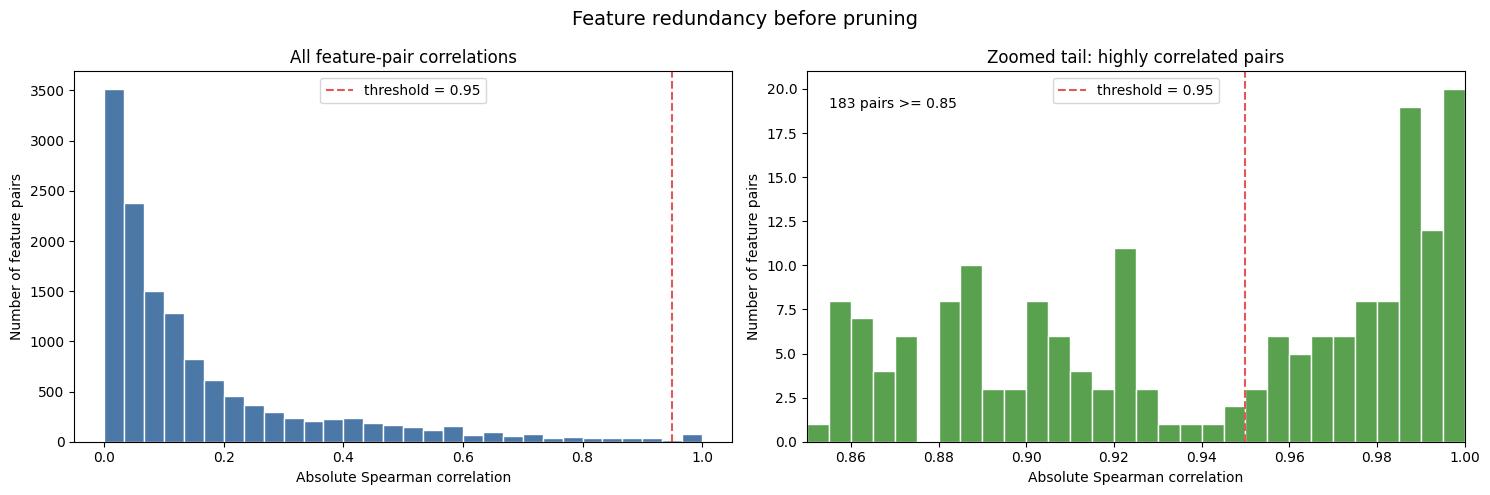

In [8]:
# Uses feature values only; labels are not used for feature selection.
absolute_corr = labeled[raw_features].replace([np.inf, -np.inf], np.nan).corr(method='spearman').abs()
upper_triangle = absolute_corr.where(np.triu(np.ones(absolute_corr.shape, dtype=bool), k=1))
pairwise_abs_corr = upper_triangle.stack().rename('absolute_spearman').reset_index()

pruning_summary = pd.DataFrame({
    'stage': ['Supplied features', 'After correlation pruning'],
    'feature_count': [len(raw_features), len(selected_features)],
    'description': ['All feat_ columns in test.csv', f'Features retained for selected_features (threshold = {CORR_THRESHOLD})'],
})
display(pruning_summary)

# Use two views: the full distribution and a zoomed-in view of highly correlated pairs.
correlation_values = pairwise_abs_corr['absolute_spearman']
tail_values = correlation_values[correlation_values >= 0.85]
tail_bins = np.linspace(0.85, 1.0, 31)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(correlation_values, bins=30, color='#4C78A8', edgecolor='white')
axes[0].axvline(CORR_THRESHOLD, color='#E45756', linestyle='--', label=f'threshold = {CORR_THRESHOLD}')
axes[0].set_xlabel('Absolute Spearman correlation')
axes[0].set_ylabel('Number of feature pairs')
axes[0].set_title('All feature-pair correlations')
axes[0].legend()

axes[1].hist(tail_values, bins=tail_bins, color='#59A14F', edgecolor='white')
axes[1].axvline(CORR_THRESHOLD, color='#E45756', linestyle='--', label=f'threshold = {CORR_THRESHOLD}')
axes[1].set_xlim(0.85, 1.0)
axes[1].set_xlabel('Absolute Spearman correlation')
axes[1].set_ylabel('Number of feature pairs')
axes[1].set_title('Zoomed tail: highly correlated pairs')
axes[1].text(0.855, axes[1].get_ylim()[1] * 0.90, f'{len(tail_values)} pairs >= 0.85', fontsize=10)
axes[1].legend()

fig.suptitle('Feature redundancy before pruning', fontsize=14)
plt.tight_layout()
plt.show()

The table records the starting and final feature counts, while the histogram shows the distribution of pairwise absolute Spearman correlations; the dashed line is the pruning threshold. The rationale for the chosen pruning threshold of 0.95 is detailed in later sections after Model Selection.

### 3.2 Feature Engineering 2: Graph Features

The transaction graph was constructed and used to derive static connectivity features (in-degree and out-degree). Additional neighbour-risk features were generated later during the two-stage model process using Stage 1 predictions and are described in the Model Validation section.

In [9]:
# Give every unique transaction a stable integer row in the graph.
nodes = (pd.concat([train[['txId', 'time_step']], test[['txId', 'time_step']]], ignore_index=True)
           .drop_duplicates('txId').reset_index(drop=True))
position = pd.Series(np.arange(len(nodes)), index=nodes['txId'])          # txId -> row number in `nodes`
node_step = nodes['time_step'].to_numpy()                                 # the time step of every node
print(f'graph nodes indexed: {len(nodes):,} unique transactions')
tick('graph node index ready')

# Translate edge endpoints from transaction IDs to graph row numbers.
src = position.reindex(edges['txId1']).to_numpy(); dst = position.reindex(edges['txId2']).to_numpy()
ok = ~(np.isnan(src) | np.isnan(dst))
known_endpoint_count = int(ok.sum())
src, dst = src[ok].astype(np.int64), dst[ok].astype(np.int64)
print(f'edge endpoints mapped: {known_endpoint_count:,}/{len(edges):,} records have known endpoints')
tick('edge endpoints mapped')

# Keep only same-step edges and remove self-loops.
same_step = node_step[src] == node_step[dst]
self_loop = src == dst
keep = same_step & ~self_loop
retained_edge_records = int(keep.sum())
A = sp.csr_matrix((np.ones(keep.sum(), dtype=np.float32), (src[keep], dst[keep])), shape=(len(nodes),) * 2)
duplicate_edges_collapsed = retained_edge_records - A.nnz
A.data[:] = 1.0                                                           # repeated edge records become one binary adjacency entry
print(f'adjacency built: {retained_edge_records:,} retained records -> {A.nnz:,} unique directed edges')
tick('adjacency matrix ready')
AT = A.T.tocsr()                                                          # the reversed graph
out_deg = np.asarray(A.sum(axis=1)).ravel()                               # how many transactions each node funds
in_deg = np.asarray(A.sum(axis=0)).ravel()                                # how many transactions fund each node

# features and labels for every node, in the same row order as `nodes`
every = (pd.concat([train.drop(columns='label'), test.drop(columns='index')], ignore_index=True)
           .drop_duplicates('txId').set_index('txId'))
def feature_matrix(cols):
    '''Features as a numeric matrix, one row per node. Infinities and missing values become 0.'''
    return every.reindex(nodes['txId'])[list(cols)].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=np.float32)
node_label = train.set_index('txId')['label'].reindex(nodes['txId']).to_numpy()   # NaN for unlabeled and test rows
is_labeled = np.isin(node_label, [0, 1])
is_test = nodes['txId'].isin(test['txId']).to_numpy()
selected_features_matrix = feature_matrix(selected_features)              # every node, the selected raw columns
print(f'graph-aligned data ready: {selected_features_matrix.shape[1]} features x {selected_features_matrix.shape[0]:,} nodes | {int(is_labeled.sum()):,} labelled | {int(is_test.sum()):,} test')
tick('features and labels aligned')
print(f'{len(nodes)} nodes | {A.nnz} same-step directed edges | {int(((in_deg + out_deg)[is_test] == 0).sum())} test transactions have no edges')
tick('graph ready')

graph nodes indexed: 157,101 unique transactions
[  11.2s] graph node index ready
edge endpoints mapped: 175,918/234,355 records have known endpoints
[  11.3s] edge endpoints mapped
adjacency built: 175,918 retained records -> 175,918 unique directed edges
[  11.3s] adjacency matrix ready
graph-aligned data ready: 101 features x 157,101 nodes | 31,235 labelled | 15,329 test
[  11.7s] features and labels aligned
157101 nodes | 175918 same-step directed edges | 3891 test transactions have no edges
[  11.7s] graph ready


#### Graph diagnostics: Exploring graph connectivity and Fraud

Key Takeaways:
1. Training transactions have a median degree of 2, compared with 1 for test transactions.
2. No labelled training transaction is isolated, while many test transactions are isolated.
3. Q2 has the highest fraud rate at 17.50%. 

Degree is therefore useful as a contextual feature rather than a standalone fraud rule.


,stage,edge_records
0,Raw edge records,234355
1,Both endpoints found in train/test nodes,175918
2,Same-time-step edge records,175918
3,After removing self-loops,175918
4,Unique binary adjacency entries,175918


,quantity,count
0,Unique transaction nodes,157101
1,Test transactions,15329
2,Isolated test transactions,3891
3,Duplicate edge records collapsed,0


,split,median_total_degree,mean_total_degree,mean_in_degree,mean_out_degree,zero_degree_count
0,Labelled train,2.0,2.866,1.763,1.102,0
1,Test,1.0,1.660,0.830,0.830,3891


,transactions,mean_degree,fraud_rate
degree_group,,,
Q1 lowest,6247,1.0000,0.1308
Q2,6247,1.0554,0.1750
Q3,6247,2.0000,0.1065
Q4,6247,2.3315,0.1372
Q5 highest,6247,7.9413,0.0339


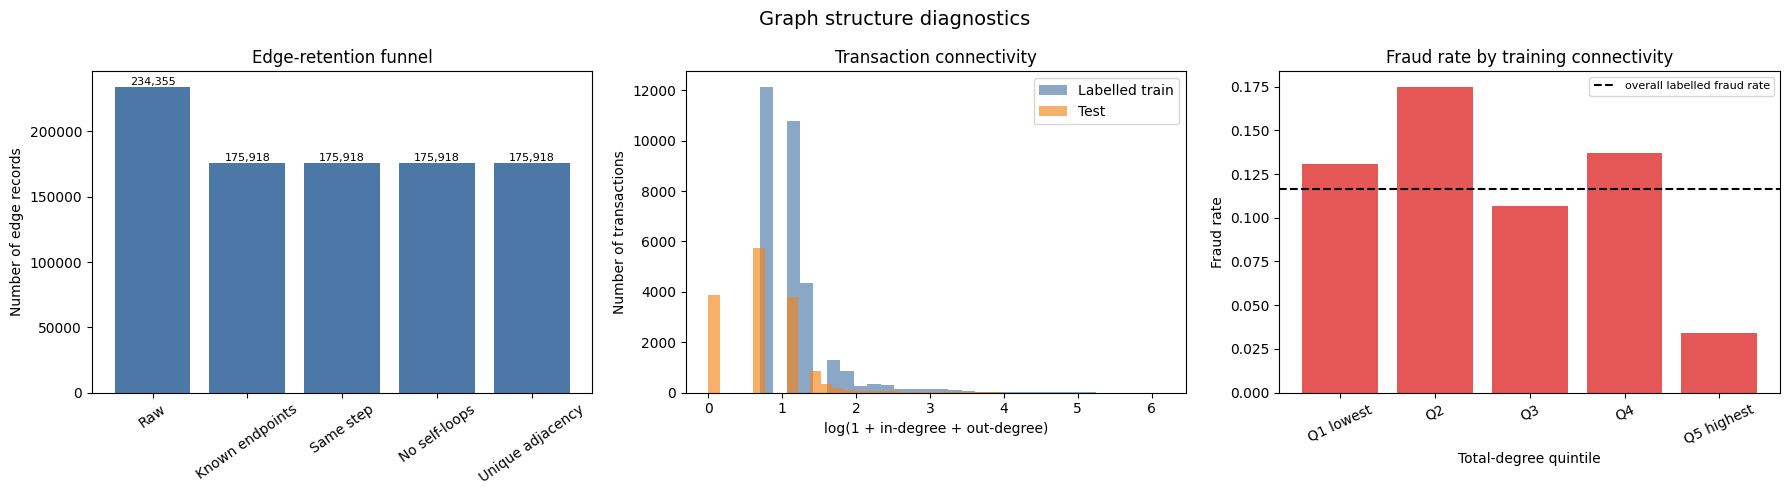

In [10]:
# Audit the edge-list filtering.
edge_filter_summary = pd.DataFrame({
    'stage': [
        'Raw edge records',
        'Both endpoints found in train/test nodes',
        'Same-time-step edge records',
        'After removing self-loops',
        'Unique binary adjacency entries',
    ],
    'edge_records': [
        len(edges),
        known_endpoint_count,
        int(same_step.sum()),
        retained_edge_records,
        A.nnz,
    ],
})
display(edge_filter_summary)

graph_summary = pd.DataFrame({
    'quantity': [
        'Unique transaction nodes',
        'Test transactions',
        'Isolated test transactions',
        'Duplicate edge records collapsed',
    ],
    'count': [
        len(nodes),
        int(is_test.sum()),
        int(((in_deg + out_deg)[is_test] == 0).sum()),
        duplicate_edges_collapsed,
    ],
})
display(graph_summary)

degree = in_deg + out_deg
degree_summary = pd.DataFrame({
    'split': ['Labelled train', 'Test'],
    'median_total_degree': [np.median(degree[is_labeled]), np.median(degree[is_test])],
    'mean_total_degree': [degree[is_labeled].mean(), degree[is_test].mean()],
    'mean_in_degree': [in_deg[is_labeled].mean(), in_deg[is_test].mean()],
    'mean_out_degree': [out_deg[is_labeled].mean(), out_deg[is_test].mean()],
    'zero_degree_count': [(degree[is_labeled] == 0).sum(), (degree[is_test] == 0).sum()],
})
display(degree_summary.round(3))

# Descriptive label check: compare fraud rates across connectivity quantiles in labelled training data.
labelled_degree = pd.DataFrame({
    'total_degree': degree[is_labeled],
    'label': node_label[is_labeled].astype(int),
})
labelled_degree['degree_group'] = pd.qcut(
    labelled_degree['total_degree'].rank(method='first'),
    q=5,
    labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'],
)
fraud_by_degree = (
    labelled_degree.groupby('degree_group', observed=True)
    .agg(
        transactions=('label', 'size'),
        mean_degree=('total_degree', 'mean'),
        fraud_rate=('label', 'mean'),
    )
)
display(fraud_by_degree.round(4))

# Visual diagnostics: edge-retention funnel, connectivity distribution, and labelled fraud rate by degree.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

funnel_labels = ['Raw', 'Known endpoints', 'Same step', 'No self-loops', 'Unique adjacency']
funnel_counts = edge_filter_summary['edge_records'].to_numpy()
axes[0].bar(funnel_labels, funnel_counts, color='#4C78A8')
for i, count in enumerate(funnel_counts):
    axes[0].text(i, count, f'{count:,}', ha='center', va='bottom', fontsize=8)
axes[0].set_title('Edge-retention funnel')
axes[0].set_ylabel('Number of edge records')
axes[0].tick_params(axis='x', rotation=35)

for mask, label, colour in [(is_labeled, 'Labelled train', '#4C78A8'), (is_test, 'Test', '#F58518')]:
    axes[1].hist(np.log1p(degree[mask]), bins=30, alpha=0.65, label=label, color=colour)
axes[1].set_title('Transaction connectivity')
axes[1].set_xlabel('log(1 + in-degree + out-degree)')
axes[1].set_ylabel('Number of transactions')
axes[1].legend()

axes[2].bar(fraud_by_degree.index.astype(str), fraud_by_degree['fraud_rate'], color='#E45756')
axes[2].axhline(labeled['label'].mean(), color='black', linestyle='--', label='overall labelled fraud rate')
axes[2].set_title('Fraud rate by training connectivity')
axes[2].set_xlabel('Total-degree quintile')
axes[2].set_ylabel('Fraud rate')
axes[2].tick_params(axis='x', rotation=25)
axes[2].legend(fontsize=8)

fig.suptitle('Graph structure diagnostics', fontsize=14)
plt.tight_layout()
plt.show()

### 3.3 Feature Engineering 3: Normalising drifting features

Some features changed scale across time. For these features, raw values were replaced with within-time-step z-scores. This allowed the model to compare each transaction with others from the same period and reduced the influence of time-related changes in the data.

In [11]:
# SETTINGS for the normalisation step
TIME_THRESHOLD = 0.9       # a column is 'clock-like' if |Spearman correlation with the time step| is at least 0.9
FLIP_MIN_STRENGTH = 0.03   # a 'direction flip' counts only if both the early and the late AUC are at least this far from 0.5
EPS = 1e-6                 # tiny number added to a step's standard deviation so a constant column cannot divide by zero

# part A: the per-step z-score of every column for every node (needs no labels at all)
step_frame = pd.DataFrame(selected_features_matrix, columns=selected_features); step_frame['step'] = node_step
grouped = step_frame.groupby('step')[selected_features]                    # one group of rows per time step
step_mean, step_std = grouped.transform('mean'), grouped.transform('std').fillna(0.0)    # each row gets its own step's mean and std
Z_matrix = ((step_frame[selected_features] - step_mean) / (step_std + EPS)).to_numpy(dtype=np.float32)  # (value - step mean) / step std
col_index = {c: i for i, c in enumerate(selected_features)}                # column name -> position in the matrices

# part B: which columns drift? Decided from the labeled training rows only
def univariate_auc(Xm, y):
    '''AUC of each column on its own, computed from ranks: 0.5 = no signal, above 0.5 = higher values mean fraud.'''
    ranks = pd.DataFrame(Xm).rank().to_numpy(); pos = y == 1
    n_pos, n_neg = pos.sum(), (~pos).sum()
    return (ranks[pos].sum(axis=0) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)    # the rank-sum form of the AUC

def clean(frame, cols):
    '''A dataframe slice as a numeric matrix, infinities and missing values replaced by 0.'''
    return frame[cols].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=np.float32)

def drift_columns(frame_fit, columns, verbose=False):
    '''Return clock-like and direction-flipping columns, using only `frame_fit`.'''
    time_corr = frame_fit[columns].corrwith(frame_fit['time_step'], method='spearman').abs()
    clock = [c for c in columns if time_corr[c] >= TIME_THRESHOLD]                      # rule 1: the column tracks the clock
    steps = np.unique(frame_fit['time_step']); early_steps = steps[: len(steps) // 2]   # the first half of the training steps
    is_early = frame_fit['time_step'].isin(early_steps).to_numpy()
    Xm, y = clean(frame_fit, columns), frame_fit['label'].to_numpy()
    a_early, a_late = univariate_auc(Xm[is_early], y[is_early]), univariate_auc(Xm[~is_early], y[~is_early])
    flip_mask = ((a_early - 0.5) * (a_late - 0.5) < 0) & (np.minimum(abs(a_early - 0.5), abs(a_late - 0.5)) >= FLIP_MIN_STRENGTH)
    flips = [c for c, is_flip in zip(columns, flip_mask) if is_flip]                    # rule 2: the relationship with fraud reverses

    if verbose:
        drift_report = pd.DataFrame({
            'abs_spearman_time': time_corr.reindex(columns).to_numpy(),
            'early_auc': a_early,
            'late_auc': a_late,
            'clock_like': [c in clock for c in columns],
            'direction_flip': flip_mask,
            'normalise': [c in set(clock) | set(flips) for c in columns],
        }, index=columns)
        print(f'drift rules: |Spearman(time)| >= {TIME_THRESHOLD:.2f}; flip strength >= {FLIP_MIN_STRENGTH:.2f} from AUC = 0.50')
        print(f'training steps used: {steps.min()}-{steps.max()} | early steps: {early_steps.min()}-{early_steps.max()} | late steps: {steps[len(early_steps):].min()}-{steps[len(early_steps):].max()}')
        print(f'clock-like: {len(clock)} | direction-flipping: {len(flips)} | normalised: {int(drift_report.normalise.sum())}')
        print('Evidence for columns selected for normalisation:')
        display(drift_report[drift_report['normalise']].sort_values(['direction_flip', 'abs_spearman_time'], ascending=[False, False]).round(4))

    return clock, flips

def normalised_matrix(clock, flips):
    '''The selected transaction columns, replacing drifting columns with per-step z-scores.'''
    X = selected_features_matrix.copy()
    idx = [col_index[c] for c in sorted(set(clock) | set(flips))]
    X[:, idx] = Z_matrix[:, idx]  # swap in the z-scores; the other 96 stay raw
    return X

clock, flips = drift_columns(labeled, selected_features, verbose=True) # for the final model: all labeled rows
DRIFT = sorted(set(clock) | set(flips))
print('clock-like columns:', clock)
print('direction-flipping columns:', flips)
print(f'-> {len(DRIFT)} of {len(selected_features)} columns are normalised; the other {len(selected_features) - len(DRIFT)} stay raw')
X_final = normalised_matrix(clock, flips) # the matrix the final model is trained on
tick('normalised feature matrix ready')

drift rules: |Spearman(time)| >= 0.90; flip strength >= 0.03 from AUC = 0.50
training steps used: 1-35 | early steps: 1-17 | late steps: 18-35
clock-like: 2 | direction-flipping: 3 | normalised: 5
Evidence for columns selected for normalisation:


,abs_spearman_time,early_auc,late_auc,clock_like,direction_flip,normalise
feat_2,0.5156,0.6391,0.3899,False,True,True
feat_109,0.4620,0.5536,0.3869,False,True,True
feat_3,0.4419,0.3707,0.6370,False,True,True
feat_103,0.9897,0.7786,0.5303,True,False,True
feat_139,0.9587,0.7414,0.4980,True,False,True


clock-like columns: ['feat_139', 'feat_103']
direction-flipping columns: ['feat_109', 'feat_2', 'feat_3']
-> 5 of 101 columns are normalised; the other 96 stay raw
[  13.2s] normalised feature matrix ready


Features selected for normalisation: 5 | early steps: 1-17 | late steps: 18-35
AUC = 0.50 means no single-feature ranking signal; values on opposite sides of 0.50 indicate a direction flip.


,reason,raw |time correlation|,after z-score |time correlation|,early fraud AUC,late fraud AUC
feature,,,,,
feat_103,clock-like,0.996,0.180,0.779,0.530
feat_109,direction flip,0.571,0.291,0.554,0.387
feat_139,clock-like,0.962,0.025,0.741,0.498
feat_2,direction flip,0.602,0.092,0.639,0.390
feat_3,direction flip,0.513,0.046,0.371,0.637


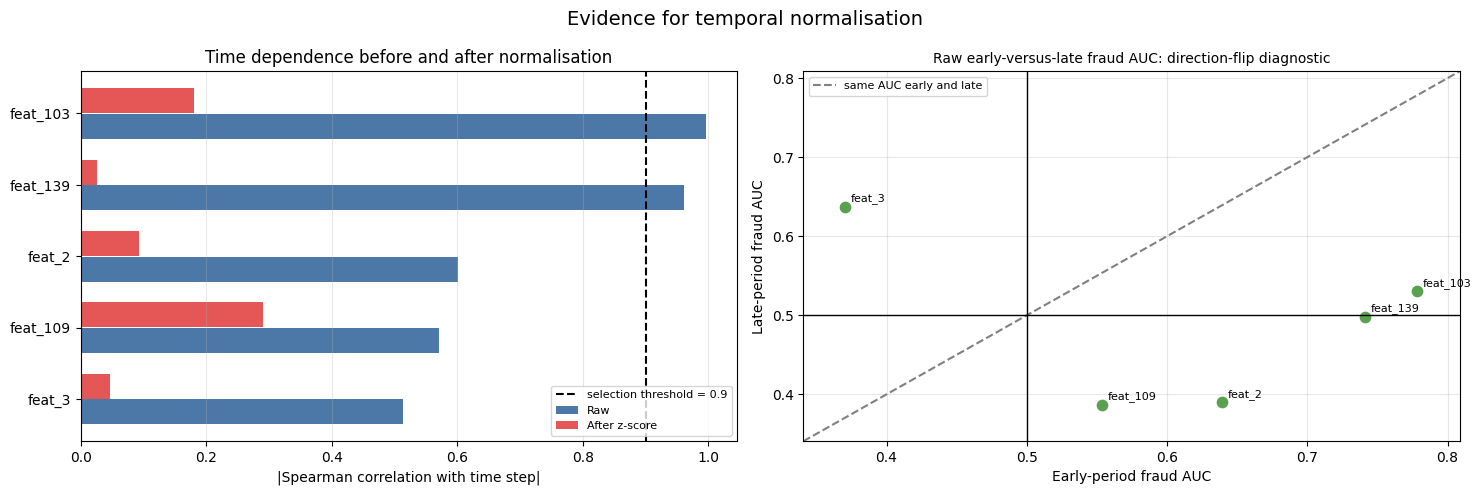

In [12]:
# SETTINGS: set to False to skip the evidence table and the explanatory figure 
RUN_RATIONALE = True

if RUN_RATIONALE:
    # Evidence uses all node feature values for time drift and labelled rows for early/late fraud AUC.
    ranked_step = pd.Series(node_step).rank()
    corr_with_step = lambda M: pd.DataFrame(M, columns=selected_features).rank().corrwith(ranked_step).abs()
    raw_corr, z_corr = corr_with_step(selected_features_matrix), corr_with_step(Z_matrix)
    lab_rows = np.where(is_labeled)[0]
    y_lab = node_label[lab_rows].astype(int)
    labelled_steps = np.unique(node_step[lab_rows])
    early_steps = labelled_steps[:len(labelled_steps) // 2]
    early_mask = np.isin(node_step[lab_rows], early_steps)

    # One compact table: the measured evidence and the rule that selected each feature.
    evidence_rows = []
    for c in DRIFT:
        j = col_index[c]
        early_auc = univariate_auc(selected_features_matrix[lab_rows, j][early_mask].reshape(-1, 1), y_lab[early_mask])[0]
        late_auc = univariate_auc(selected_features_matrix[lab_rows, j][~early_mask].reshape(-1, 1), y_lab[~early_mask])[0]
        if c in clock and c in flips:
            reason = 'clock-like + direction flip'
        elif c in clock:
            reason = 'clock-like'
        else:
            reason = 'direction flip'
        evidence_rows.append({
            'feature': c,
            'reason': reason,
            'raw |time correlation|': raw_corr[c],
            'after z-score |time correlation|': z_corr[c],
            'early fraud AUC': early_auc,
            'late fraud AUC': late_auc,
        })
    drift_evidence = pd.DataFrame(evidence_rows).set_index('feature')
    print(f'Features selected for normalisation: {len(DRIFT)} | early steps: {early_steps.min()}-{early_steps.max()} | late steps: {labelled_steps[len(early_steps):].min()}-{labelled_steps[len(early_steps):].max()}')
    print('AUC = 0.50 means no single-feature ranking signal; values on opposite sides of 0.50 indicate a direction flip.')
    display(drift_evidence.round(3))

    # Visual 1: normalisation reduces the time correlation of the selected features.
    feature_order = drift_evidence.sort_values('raw |time correlation|').index
    y_pos = np.arange(len(feature_order))
    fig, axes = plt.subplots(1, 2, figsize=(15, max(5, 0.45 * len(feature_order))))
    axes[0].barh(y_pos - 0.18, drift_evidence.loc[feature_order, 'raw |time correlation|'], height=0.35, label='Raw', color='#4C78A8')
    axes[0].barh(y_pos + 0.18, drift_evidence.loc[feature_order, 'after z-score |time correlation|'], height=0.35, label='After z-score', color='#E45756')
    axes[0].set_yticks(y_pos); axes[0].set_yticklabels(feature_order)
    axes[0].set_xlabel('|Spearman correlation with time step|')
    axes[0].set_title('Time dependence before and after normalisation')
    axes[0].axvline(TIME_THRESHOLD, color='black', linestyle='--', label=f'selection threshold = {TIME_THRESHOLD}')
    axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, axis='x')

    # Visual 2: diagnostic for identifying unstable fraud relationships. Points on opposite sides of 0.50 have a direction flip and z-scoring does not remove this flip.
    axes[1].scatter(drift_evidence['early fraud AUC'], drift_evidence['late fraud AUC'], color='#59A14F', s=55)
    for feature, row in drift_evidence.iterrows():
        axes[1].annotate(feature, (row['early fraud AUC'], row['late fraud AUC']), xytext=(4, 4), textcoords='offset points', fontsize=8)
    auc_values = drift_evidence[['early fraud AUC', 'late fraud AUC']].to_numpy().ravel()
    lower, upper = max(0.0, auc_values.min() - 0.03), min(1.0, auc_values.max() + 0.03)
    lower, upper = min(lower, 0.47), max(upper, 0.53)
    axes[1].plot([lower, upper], [lower, upper], color='grey', linestyle='--', label='same AUC early and late')
    axes[1].axvline(0.5, color='black', linewidth=1); axes[1].axhline(0.5, color='black', linewidth=1)
    axes[1].set_xlim(lower, upper); axes[1].set_ylim(lower, upper)
    axes[1].set_xlabel('Early-period fraud AUC'); axes[1].set_ylabel('Late-period fraud AUC')
    axes[1].set_title('Raw early-versus-late fraud AUC: direction-flip diagnostic', fontsize=10)
    axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
    fig.suptitle('Evidence for temporal normalisation', fontsize=14)
    plt.tight_layout(); plt.show()
else:
    print('normalisation evidence skipped (RUN_RATIONALE = False)')

## 4. Model selection

Candidate models are compared using the same engineered features, temporal validation folds, and seed 42. Mean PR-AUC is the main selection metric, while ROC-AUC is reported as a secondary measure.

ROC-AUC measures how well the model ranks fraudulent transactions above legitimate ones overall. PR-AUC focuses more on the minority fraud class by evaluating the precision-recall trade-off. Both use continuous model scores rather than a fixed classification threshold.

### 4.1 LightGBM configuration

The candidate models use fixed configurations during comparison so that differences in validation performance reflect the model family rather than extensive per-model tuning. The LightGBM settings below are also reused by the final model.

In [13]:
# SETTINGS: LightGBM hyper-parameters used by the candidate and final models.
LGBM_PARAMS = dict(n_estimators=500,   # number of trees
                   learning_rate=0.05,                  # how much each new tree is allowed to change the prediction
                   num_leaves=31, min_child_samples=30, # tree size limits (guard against over-fitting)
                   subsample=0.8, subsample_freq=1,     # every tree sees a random 80% of the rows ...
                   colsample_bytree=0.8,                # ... and a random 80% of the columns
                   reg_alpha=0.1, reg_lambda=1.0,       # light L1 / L2 regularisation
                   objective='binary', random_state=42, n_jobs=-1, verbosity=-1)

# Rank turns predictions into percentiles; this preserves ordering for the ranking metric and seed averages.
rank = lambda p: pd.Series(p).rank(pct=True).to_numpy()

### 4.2 Model comparison

This experiment compares model families on the same selected and temporally normalised transaction features. It does not include graph features, so the effect of the two-stage graph pipeline will be evaluated separately in Section 5. The first four short windows are used for model selection; the recent and long-horizon windows are reported as checks.

[  34.6s] model comparison: fold 1: train 1-15 -> predict 16-19 complete
[  53.3s] model comparison: fold 2: train 1-19 -> predict 20-23 complete
[  73.3s] model comparison: fold 3: train 1-23 -> predict 24-27 complete
[  95.4s] model comparison: fold 4: train 1-27 -> predict 28-31 complete
[ 120.0s] model comparison: recent 4-step: train 1-31 -> predict 32-35 complete
[ 135.5s] model comparison: 14-step: train 1-15 -> predict 16-29 complete
[ 153.2s] model comparison: 14-step: train 1-21 -> predict 22-35 complete


,model,window,kind,seconds,ROC AUC,PR-AUC,F1,worst-step AUC
0,Logistic regression,fold 1: train 1-15 -> predict 16-19,selection,0.1398,0.9672,0.7776,0.5930,0.9469
1,Decision tree,fold 1: train 1-15 -> predict 16-19,selection,0.6804,0.9780,0.9423,0.8438,0.9513
2,Random forest,fold 1: train 1-15 -> predict 16-19,selection,2.8578,0.9928,0.9829,0.6777,0.9869
3,Extra trees,fold 1: train 1-15 -> predict 16-19,selection,0.9562,0.9888,0.9696,0.6777,0.9780
4,Neural network (MLP),fold 1: train 1-15 -> predict 16-19,selection,4.0370,0.9482,0.7688,0.5488,0.9135
5,LightGBM,fold 1: train 1-15 -> predict 16-19,selection,4.1940,0.9930,0.9857,0.6777,0.9865
6,"LightGBM, shallow",fold 1: train 1-15 -> predict 16-19,selection,1.8804,0.9926,0.9840,0.6777,0.9880
7,Logistic regression,fold 2: train 1-19 -> predict 20-23,selection,0.1517,0.9359,0.6132,0.5458,0.8997
8,Decision tree,fold 2: train 1-19 -> predict 20-23,selection,0.8301,0.8926,0.8371,0.8017,0.7757
9,Random forest,fold 2: train 1-19 -> predict 20-23,selection,3.6969,0.9806,0.9488,0.7966,0.8922


,mean_PR_AUC,PR_AUC_SE,mean_ROC_AUC,mean_F1,mean_worst_step_AUC
model,,,,,
Logistic regression,0.6025,0.0747,0.9040,0.4951,0.8327
Decision tree,0.8986,0.0280,0.9496,0.7968,0.9049
Random forest,0.9694,0.0088,0.9893,0.7079,0.9616
Extra trees,0.9506,0.0125,0.9844,0.7025,0.9566
Neural network (MLP),0.8442,0.0325,0.9589,0.6453,0.9064
LightGBM,0.9773,0.0063,0.9933,0.7088,0.9781
"LightGBM, shallow",0.9610,0.0162,0.9887,0.7077,0.9656


best node-level model by mean PR-AUC: LightGBM


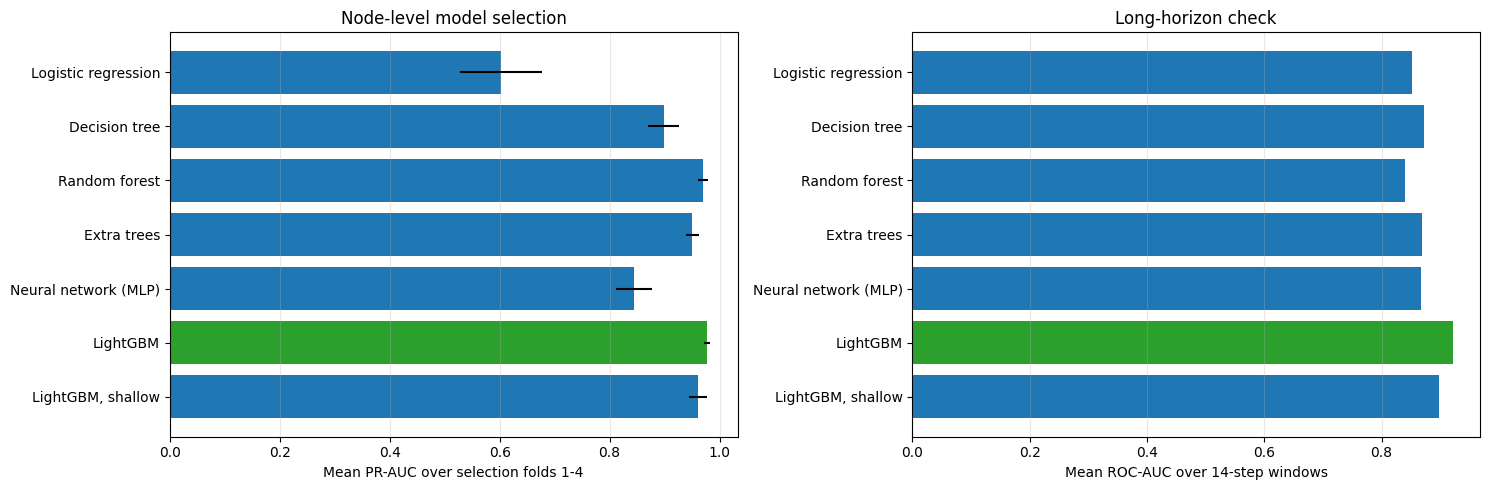

In [ ]:
# Optional diagnostic: all candidate models use seed 42 and the same temporal windows.
RUN_MODEL_COMPARISON = True
MODEL_COMPARISON_SEED = 42
MODEL_COMPARISON_WINDOWS = [
    ('fold 1: train 1-15 -> predict 16-19', 'selection', 15, 16, 19),
    ('fold 2: train 1-19 -> predict 20-23', 'selection', 19, 20, 23),
    ('fold 3: train 1-23 -> predict 24-27', 'selection', 23, 24, 27),
    ('fold 4: train 1-27 -> predict 28-31', 'selection', 27, 28, 31),
    ('recent 4-step: train 1-31 -> predict 32-35', 'locked', 31, 32, 35),
    ('14-step: train 1-15 -> predict 16-29', 'long', 15, 16, 29),
    ('14-step: train 1-21 -> predict 22-35', 'long', 21, 22, 35),
]

NODE_MODEL_NAMES = [
    'Logistic regression', 'Decision tree', 'Random forest', 'Extra trees',
    'Neural network (MLP)', 'LightGBM', 'LightGBM, shallow',
]


def scaled_model(factory):
    """Return a predictor that fits scaling on training rows only."""
    def predict(X_fit, y_fit, X_valid):
        X_fit, X_valid = np.clip(X_fit, -50, 50), np.clip(X_valid, -50, 50)
        scaler = StandardScaler().fit(X_fit)
        model = factory()
        model.fit(scaler.transform(X_fit), y_fit)
        return model.predict_proba(scaler.transform(X_valid))[:, 1]
    return predict


def unscaled_model(factory):
    """Return a predictor for tree-based models that do not need scaling."""
    def predict(X_fit, y_fit, X_valid):
        model = factory()
        model.fit(X_fit, y_fit)
        return model.predict_proba(X_valid)[:, 1]
    return predict


NODE_MODELS = {
    'Logistic regression': scaled_model(
        lambda: LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000,
                                    random_state=MODEL_COMPARISON_SEED)
    ),
    'Decision tree': unscaled_model(
        lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=30,
                                       random_state=MODEL_COMPARISON_SEED)
    ),
    'Random forest': unscaled_model(
        lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                       n_jobs=-1, random_state=MODEL_COMPARISON_SEED)
    ),
    'Extra trees': unscaled_model(
        lambda: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3,
                                     n_jobs=-1, random_state=MODEL_COMPARISON_SEED)
    ),
    'Neural network (MLP)': scaled_model(
        lambda: MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                              early_stopping=True, max_iter=200,
                              random_state=MODEL_COMPARISON_SEED)
    ),
    'LightGBM': unscaled_model(
        lambda: LGBMClassifier(**{**LGBM_PARAMS, 'random_state': MODEL_COMPARISON_SEED})
    ),
    'LightGBM, shallow': unscaled_model(
        lambda: LGBMClassifier(
            **{**LGBM_PARAMS, 'random_state': MODEL_COMPARISON_SEED,
               'max_depth': 3, 'num_leaves': 8, 'n_estimators': 600,
               'reg_lambda': 10}
        )
    ),
}


def comparison_metrics(y_true, steps, probabilities, training_fraud_rate):
    """Calculate ranking metrics without using a fixed probability threshold."""
    scores = rank(probabilities)
    flagged = scores >= np.quantile(scores, 1 - training_fraud_rate)
    step_auc = [
        roc_auc_score(y_true[steps == step], scores[steps == step])
        for step in np.unique(steps)
        if 0 < y_true[steps == step].sum() < (steps == step).sum()
    ]
    return {
        'ROC AUC': roc_auc_score(y_true, scores),
        'PR-AUC': average_precision_score(y_true, scores),
        'F1': f1_score(y_true, flagged),
        'worst-step AUC': min(step_auc) if step_auc else np.nan,
    }


if RUN_MODEL_COMPARISON:
    comparison_rows = []
    for window_name, window_kind, fit_end, valid_start, valid_end in MODEL_COMPARISON_WINDOWS:
        frame_fit = labeled[labeled.time_step <= fit_end]
        X_window = normalised_matrix(*drift_columns(frame_fit, selected_features))
        fit_idx_window = np.where(is_labeled & (node_step <= fit_end))[0]
        valid_idx_window = np.where(
            is_labeled & (node_step >= valid_start) & (node_step <= valid_end)
        )[0]
        y_fit = node_label[fit_idx_window].astype(int)
        y_valid = node_label[valid_idx_window].astype(int)
        steps_valid = node_step[valid_idx_window]

        for model_name, predict_model in NODE_MODELS.items():
            start = perf_counter()
            probabilities = predict_model(
                X_window[fit_idx_window], y_fit, X_window[valid_idx_window]
            )
            metrics = comparison_metrics(
                y_valid, steps_valid, probabilities, y_fit.mean()
            )
            comparison_rows.append({
                'model': model_name,
                'window': window_name,
                'kind': window_kind,
                'seconds': perf_counter() - start,
                **metrics,
            })
        tick(f'model comparison: {window_name} complete')

    model_comparison_perfold = pd.DataFrame(comparison_rows)
    display(model_comparison_perfold.round(4))

    selection_rows = model_comparison_perfold[
        model_comparison_perfold.kind == 'selection'
    ]
    model_comparison_summary = (
        selection_rows.groupby('model')
        .agg(
            mean_PR_AUC=('PR-AUC', 'mean'),
            PR_AUC_SE=('PR-AUC', lambda values: values.std(ddof=1) / np.sqrt(len(values))),
            mean_ROC_AUC=('ROC AUC', 'mean'),
            mean_F1=('F1', 'mean'),
            mean_worst_step_AUC=('worst-step AUC', 'mean'),
        )
        .reindex(NODE_MODEL_NAMES)
    )
    display(model_comparison_summary.round(4))

    best_node_model = model_comparison_summary.mean_PR_AUC.idxmax()
    print(f'best node-level model by mean PR-AUC: {best_node_model}')

    long_summary = (
        model_comparison_perfold[model_comparison_perfold.kind == 'long']
        .groupby('model')['ROC AUC'].mean()
        .reindex(NODE_MODEL_NAMES)
    )
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    colours = ['tab:green' if name == best_node_model else 'tab:blue'
               for name in NODE_MODEL_NAMES]
    axes[0].barh(
        NODE_MODEL_NAMES[::-1], model_comparison_summary.mean_PR_AUC[::-1],
        xerr=model_comparison_summary.PR_AUC_SE[::-1], color=colours[::-1]
    )
    axes[0].set_xlabel('Mean PR-AUC over selection folds 1-4')
    axes[0].set_title('Node-level model selection')
    axes[0].grid(alpha=0.3, axis='x')

    axes[1].barh(NODE_MODEL_NAMES[::-1], long_summary[::-1], color=colours[::-1])
    axes[1].set_xlabel('Mean ROC-AUC over 14-step windows')
    axes[1].set_title('Long-horizon check')
    axes[1].grid(alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()
else:
    print('model comparison skipped (RUN_MODEL_COMPARISON = False)')

## 5. Final Model and Validation

This section defines and evaluates the final two-stage LightGBM pipeline. It tests the feature-selection decision, compares graph-enhanced and plain LightGBM, and evaluates temporal and seed stability.

### 5.1 Final Two-stage LightGBM implementation

Stage 1 produces cross-fitted fraud-risk scores. Graph aggregates summarise neighbouring transactions, and Stage 2 combines those graph features with the transaction features.

In [15]:
# Stage 1 uses fewer trees than Stage 2 but keeps the same base configuration.
STAGE1 = {**LGBM_PARAMS, 'n_estimators': 300}
STAGE2 = {**LGBM_PARAMS}

def stage1_scores(X, fit_idx, params, n_blocks=4):
    '''Score every node; training rows receive out-of-block scores to avoid target leakage.'''
    scores = np.zeros(len(nodes), dtype=np.float32)
    y = node_label[fit_idx].astype(int)
    rest = np.setdiff1d(np.arange(len(nodes)), fit_idx)
    scores[rest] = LGBMClassifier(**params).fit(X[fit_idx], y).predict_proba(X[rest])[:, 1]
    for block in np.array_split(np.unique(node_step[fit_idx]), n_blocks):
        in_block = np.isin(node_step[fit_idx], block)
        model = LGBMClassifier(**params).fit(X[fit_idx[~in_block]], y[~in_block])
        scores[fit_idx[in_block]] = model.predict_proba(X[fit_idx[in_block]])[:, 1]
    return scores

def neighbour_features(s):
    '''Create mean/max neighbour-risk scores plus in-degree and out-degree.'''
    def mean(M, deg):
        values = (M @ s) / np.maximum(deg, 1)
        values[deg == 0] = np.nan
        return values
    def maximum(M):
        coo = M.tocoo(); values = np.full(len(s), -np.inf, dtype=np.float32)
        np.maximum.at(values, coo.row, s[coo.col])
        values[np.isinf(values)] = np.nan
        return values
    return np.column_stack([mean(A, out_deg), mean(AT, in_deg), maximum(A), maximum(AT), in_deg, out_deg]).astype(np.float32)

def staged_predict(X, fit_idx, pred_idx, seed=42):
    '''Fit the two-stage model and return fraud probabilities for pred_idx.'''
    stage1 = stage1_scores(X, fit_idx, {**STAGE1, 'random_state': seed})
    neighbour = neighbour_features(stage1)
    y = node_label[fit_idx].astype(int)
    X_fit = np.hstack([X[fit_idx], neighbour[fit_idx]])
    X_pred = np.hstack([X[pred_idx], neighbour[pred_idx]])
    model = LGBMClassifier(**{**STAGE2, 'random_state': seed}).fit(X_fit, y)
    return model.predict_proba(X_pred)[:, 1]

### 5.2 Feature-selection sensitivity analysis

This diagnostic tests whether the correlation-pruning threshold gives a compact transaction feature set without a meaningful loss in the final two-stage pipeline.

In [ ]:
# Set to False to skip this optional diagnostic on future runs.
RUN_FEATURE_SENSITIVITY = True
EXPERIMENT_SEED = 42

if RUN_FEATURE_SENSITIVITY:
    threshold_options = [
        ('No pruning', None),
        ('Threshold 0.90', 0.90),
        ('Threshold 0.95', 0.95),
        ('Threshold 0.99', 0.99),
    ]

    # These windows match the temporal validation used.
    experiment_windows = [
        ('recent 4-step: train 1-31 -> predict 32-35', 31, 32, 35),
        ('14-step: train 1-15 -> predict 16-29', 15, 16, 29),
        ('14-step: train 1-21 -> predict 22-35', 21, 22, 35),
    ]

    def build_experiment_matrix(columns, training_frame):
        # Build the selected columns for every node, including validation nodes.
        X = feature_matrix(columns)

        # Compute within-time-step z-scores without using any labels.
        values = pd.DataFrame(X, columns=columns)
        values['step'] = node_step
        grouped = values.groupby('step')[columns]
        step_mean = grouped.transform('mean')
        step_std = grouped.transform('std').fillna(0.0)
        Z = ((values[columns] - step_mean) / (step_std + EPS)).to_numpy(dtype=np.float32)

        # Drift detection is fitted only on this window's training rows.
        clock_used, flips_used = drift_columns(training_frame, columns)
        drift_used = sorted(set(clock_used) | set(flips_used))
        column_position = {column: i for i, column in enumerate(columns)}
        drift_positions = [column_position[column] for column in drift_used]
        X[:, drift_positions] = Z[:, drift_positions]

        return X, drift_used

    sensitivity_rows = []

    for feature_set_name, threshold in threshold_options:
        for window_name, fit_end, valid_start, valid_end in experiment_windows:
            # Feature selection sees only the earlier training period.
            training_frame = labeled[labeled['time_step'] <= fit_end].copy()

            if threshold is None:
                selected_columns = raw_features
            else:
                selected_columns = greedy_correlation_prune(
                    training_frame, raw_features, threshold=threshold
                )

            X_window, drift_used = build_experiment_matrix(
                selected_columns, training_frame
            )

            fit_indices = np.where(is_labeled & (node_step <= fit_end))[0]
            valid_indices = np.where(
                is_labeled
                & (node_step >= valid_start)
                & (node_step <= valid_end)
            )[0]

            # Use the same two-stage LightGBM model as the final pipeline.
            predictions = staged_predict(
                X_window, fit_indices, valid_indices, seed=EXPERIMENT_SEED
            )
            y_valid = node_label[valid_indices].astype(int)
            validation_ranks = rank(predictions)

            sensitivity_rows.append({
                'feature_set': feature_set_name,
                'window': window_name,
                'features': len(selected_columns),
                'normalised_features': len(drift_used),
                'ROC AUC': roc_auc_score(y_valid, validation_ranks),
                'PR AUC': average_precision_score(y_valid, validation_ranks),
            })

    feature_sensitivity = pd.DataFrame(sensitivity_rows)
    display(feature_sensitivity.round(4))

    feature_sensitivity_summary = (
        feature_sensitivity
        .groupby('feature_set')
        .agg(
            mean_features=('features', 'mean'),
            mean_ROC_AUC=('ROC AUC', 'mean'),
            mean_PR_AUC=('PR AUC', 'mean'),
        )
        .sort_values('mean_PR_AUC', ascending=False)
    )
    display(feature_sensitivity_summary.round(4))
else:
    print('feature-selection sensitivity experiment skipped')

,feature_set,window,features,normalised_features,ROC AUC,PR AUC
0,No pruning,recent 4-step: train 1-31 -> predict 32-35,165,13,0.9984,0.9953
1,No pruning,14-step: train 1-15 -> predict 16-29,165,12,0.8821,0.8409
2,No pruning,14-step: train 1-21 -> predict 22-35,165,10,0.8887,0.8106
3,Threshold 0.90,recent 4-step: train 1-31 -> predict 32-35,89,5,0.9986,0.9952
4,Threshold 0.90,14-step: train 1-15 -> predict 16-29,89,5,0.9018,0.8487
5,Threshold 0.90,14-step: train 1-21 -> predict 22-35,91,5,0.8831,0.8081
6,Threshold 0.95,recent 4-step: train 1-31 -> predict 32-35,101,6,0.9986,0.9954
7,Threshold 0.95,14-step: train 1-15 -> predict 16-29,103,8,0.9217,0.8537
8,Threshold 0.95,14-step: train 1-21 -> predict 22-35,102,5,0.8881,0.8101
9,Threshold 0.99,recent 4-step: train 1-31 -> predict 32-35,137,11,0.9987,0.9955


,mean_features,mean_ROC_AUC,mean_PR_AUC
feature_set,,,
Threshold 0.95,102.0000,0.9361,0.8864
Threshold 0.99,137.6667,0.9323,0.8853
Threshold 0.90,89.6667,0.9278,0.8840
No pruning,165.0000,0.9231,0.8823


Hence, the produced set of features from Feature Engineering 1 is more useful than the full set of features.

### 5.3 Enhanced LightGBM (Feature Engineering 1–3)

The final model extends LightGBM (from Section 4.2) to use Feature Engineering 1-3. Stage 1 produces cross-fitted fraud-risk scores, graph aggregates summarise neighbouring transactions, and Stage 2 combines those neighbour-risk and degree features with the transaction features.

The raw condition uses all 165 supplied features without correlation pruning or temporal normalisation. The engineered condition uses the fixed correlation-pruned feature list selected from the labelled training data, while the temporal-drift rule is recomputed from each validation window's training rows. The within-time-step z-score statistics use feature values only and do not use labels. Plain LightGBM has no graph columns; two-stage LightGBM adds graph-derived neighbour-risk features and degree columns. All configurations use the same temporal windows and seed 42.

[3855.4s] final-model ablation: recent 4-step: train 1-31 -> predict 32-35 complete
[3881.8s] final-model ablation: 14-step: train 1-15 -> predict 16-29 complete
[3915.6s] final-model ablation: 14-step: train 1-21 -> predict 22-35 complete


,window,seed,configuration,ROC AUC,PR-AUC
0,recent 4-step: train 1-31 -> predict 32-35,42,Plain LightGBM | raw,0.9984,0.9942
1,recent 4-step: train 1-31 -> predict 32-35,42,Two-stage LightGBM | engineered,0.9986,0.9954
2,14-step: train 1-15 -> predict 16-29,42,Plain LightGBM | raw,0.8924,0.8425
3,14-step: train 1-15 -> predict 16-29,42,Two-stage LightGBM | engineered,0.9273,0.8580
4,14-step: train 1-21 -> predict 22-35,42,Plain LightGBM | raw,0.8710,0.7991
5,14-step: train 1-21 -> predict 22-35,42,Two-stage LightGBM | engineered,0.8994,0.8152


,mean_ROC_AUC,ROC_AUC_SE,mean_PR_AUC,PR_AUC_SE
configuration,,,,
Plain LightGBM | raw,0.9206,0.0394,0.8786,0.0591
Two-stage LightGBM | engineered,0.9418,0.0295,0.8895,0.0544


,,enhanced pipeline gain vs raw baseline (PR-AUC)
window,seed,
14-step: train 1-15 -> predict 16-29,42,0.0155
14-step: train 1-21 -> predict 22-35,42,0.0161
recent 4-step: train 1-31 -> predict 32-35,42,0.0012


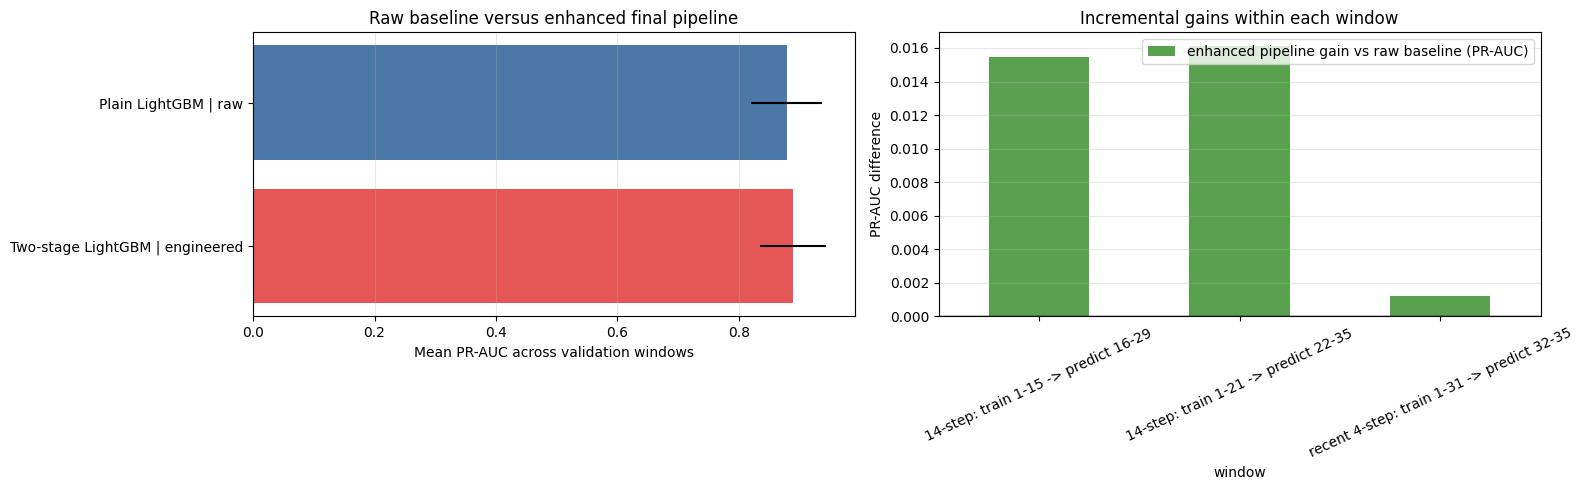

In [22]:
# Compare baseline LightGBM with the Enhanced LightGBM
RUN_FINAL_MODEL_ABLATION = True
FINAL_ABLATION_SEEDS = [42]  # keep architecture comparisons on the same seed
FINAL_ABLATION_WINDOWS = [
    ('recent 4-step: train 1-31 -> predict 32-35', 31, 32, 35),
    ('14-step: train 1-15 -> predict 16-29', 15, 16, 29),
    ('14-step: train 1-21 -> predict 22-35', 21, 22, 35),
]

# Compare the simple raw-feature baseline with the enhanced pipeline used for Submission 18.
RAW_FEATURE_MATRIX = feature_matrix(raw_features)
ABLATION_CONFIGS = [
    'Plain LightGBM | raw',
    'Two-stage LightGBM | engineered',
]


def plain_lgbm_predict(X, fit_idx, pred_idx, seed):
    """Fit one LightGBM using only the supplied transaction feature matrix."""
    y = node_label[fit_idx].astype(int)
    model = LGBMClassifier(**{**STAGE2, 'random_state': seed})
    model.fit(X[fit_idx], y)
    return model.predict_proba(X[pred_idx])[:, 1]


def fold_engineered_matrix(frame_fit):
    """Build selected and time-normalised features using this fold's training rows."""
    X = feature_matrix(selected_features)
    values = pd.DataFrame(X, columns=selected_features)
    values['step'] = node_step
    grouped = values.groupby('step')[selected_features]
    means = grouped.transform('mean')
    stds = grouped.transform('std').fillna(0.0)
    z_scores = ((values[selected_features] - means) / (stds + EPS)).to_numpy(np.float32)

    clock, flips = drift_columns(frame_fit, selected_features)
    positions = [selected_features.index(column) for column in sorted(set(clock) | set(flips))]
    X[:, positions] = z_scores[:, positions]
    return X


if RUN_FINAL_MODEL_ABLATION:
    ablation_rows = []
    for window_name, fit_end, valid_start, valid_end in FINAL_ABLATION_WINDOWS:
        frame_fit = labeled[labeled.time_step <= fit_end]
        X_raw = RAW_FEATURE_MATRIX
        X_engineered = fold_engineered_matrix(frame_fit)
        fit_idx_window = np.where(is_labeled & (node_step <= fit_end))[0]
        valid_idx_window = np.where(
            is_labeled & (node_step >= valid_start) & (node_step <= valid_end)
        )[0]
        y_valid = node_label[valid_idx_window].astype(int)

        for seed in FINAL_ABLATION_SEEDS:
            probabilities = {
                'Plain LightGBM | raw': plain_lgbm_predict(
                    X_raw, fit_idx_window, valid_idx_window, seed
                ),
                'Two-stage LightGBM | engineered': staged_predict(
                    X_engineered, fit_idx_window, valid_idx_window, seed
                ),
            }
            for configuration, probability in probabilities.items():
                scores = rank(probability)
                ablation_rows.append({
                    'window': window_name,
                    'seed': seed,
                    'configuration': configuration,
                    'ROC AUC': roc_auc_score(y_valid, scores),
                    'PR-AUC': average_precision_score(y_valid, scores),
                })
        tick(f'final-model ablation: {window_name} complete')

    final_model_ablation_perfold = pd.DataFrame(ablation_rows)
    display(final_model_ablation_perfold.round(4))

    final_model_ablation_summary = (
        final_model_ablation_perfold.groupby('configuration')
        .agg(
            mean_ROC_AUC=('ROC AUC', 'mean'),
            ROC_AUC_SE=('ROC AUC', lambda values: values.std(ddof=1) / np.sqrt(len(values))),
            mean_PR_AUC=('PR-AUC', 'mean'),
            PR_AUC_SE=('PR-AUC', lambda values: values.std(ddof=1) / np.sqrt(len(values))),
        )
        .reindex(ABLATION_CONFIGS)
    )
    display(final_model_ablation_summary.round(4))

    # Measure the validation difference between the final pipeline and the raw baseline.
    wide = final_model_ablation_perfold.pivot_table(
        index=['window', 'seed'], columns='configuration', values=['ROC AUC', 'PR-AUC']
    )
    final_model_ablation_deltas = pd.DataFrame({
        'enhanced pipeline gain vs raw baseline (PR-AUC)': (
            wide['PR-AUC']['Two-stage LightGBM | engineered']
            - wide['PR-AUC']['Plain LightGBM | raw']
        ),
    })
    display(final_model_ablation_deltas.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    summary = final_model_ablation_summary
    axes[0].barh(
        ABLATION_CONFIGS[::-1], summary.mean_PR_AUC[::-1],
        xerr=summary.PR_AUC_SE[::-1], color=['#4C78A8', '#E45756'][::-1]
    )
    axes[0].set_xlabel('Mean PR-AUC across validation windows')
    axes[0].set_title('Raw baseline versus enhanced final pipeline')
    axes[0].grid(alpha=0.3, axis='x')

    delta_means = final_model_ablation_deltas.groupby(level='window').mean()
    delta_means.plot(kind='bar', ax=axes[1], color='#59A14F')
    axes[1].axhline(0, color='black', linewidth=1)
    axes[1].set_ylabel('PR-AUC difference')
    axes[1].set_title('Incremental gains within each window')
    axes[1].tick_params(axis='x', rotation=25)
    axes[1].grid(alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()
else:
    print('final-model ablation skipped (RUN_FINAL_MODEL_ABLATION = False)')

### 5.4 Temporal validation and seed stability

The final two-stage LightGBM is evaluated on later time steps using expanding temporal windows. Seed 42 is compared with the six-seed average to show whether the final ensemble is more stable than a single random fit.

**Windows.** The recent 4-step window checks performance near the end of the labelled period. The two 14-step windows mimic the longer forecast horizon of the test set. The temporal-drift rule is recomputed from each window's training rows only; the earlier correlation-pruned feature list remains fixed. The z-score calculation is label-free and uses feature values grouped by time step.

In [ ]:
# SETTINGS for the validation
# These seeds are used for validation and for the final seed ensemble.
SEEDS = [42, 0, 1, 2, 3, 4]
RUN_VALIDATION = True          # set False to skip this section and its figures (about 5 minutes)
LONG_FIT_ENDS = [15, 21]       # the last training step of each long-horizon window; each predicts the next LONG_HORIZON steps
LONG_HORIZON = 14              # how many steps ahead the long windows predict (the test set is 1-14 steps ahead)
INCLUDE_RECENT_SHORT = True    # include the recent 4-step window (train 1-31, predict 32-35)
if RUN_VALIDATION:
    # each window is (name, last training step, first validation step, last validation step)
    WINDOWS = ([('recent 4-step: train 1-31 -> predict 32-35', 31, 32, 35)] if INCLUDE_RECENT_SHORT else []) + [(f'14-step: train 1-{e} -> predict {e + 1}-{min(e + LONG_HORIZON, 35)}', e, e + 1, min(e + LONG_HORIZON, 35)) for e in LONG_FIT_ENDS]
    store = {}                                                             # everything the figures need, per window
    print(len(SEEDS), 'seeds x', len(WINDOWS), 'windows =', len(SEEDS) * len(WINDOWS), 'model runs')
    for wname, fit_end, v_start, v_end in WINDOWS:
        fit_w = np.where(is_labeled & (node_step <= fit_end))[0]                                   # training rows of this window
        valid_w = np.where(is_labeled & (node_step >= v_start) & (node_step <= v_end))[0]          # the labeled rows to predict
        # choose the drifting columns from THIS window's training rows only, then build the matrix
        X_w = normalised_matrix(*drift_columns(labeled[labeled.time_step <= fit_end], selected_features))
        probs = {s: staged_predict(X_w, fit_w, valid_w, s) for s in SEEDS}                          # one model run per seed
        ranks_w = {s: rank(p) for s, p in probs.items()}
        half = len(SEEDS) // 2
        store[wname] = dict(y=node_label[valid_w].astype(int), steps=node_step[valid_w], fit_end=fit_end, ranks=ranks_w,
                            bag=np.mean([ranks_w[s] for s in SEEDS], axis=0),                       # the bag of all seeds
                            half_a=np.mean([ranks_w[s] for s in SEEDS[:half]], axis=0),             # first half of the seeds
                            half_b=np.mean([ranks_w[s] for s in SEEDS[half:]], axis=0))             # second half of the seeds
        tick(f'{wname} done ({len(valid_w)} validation rows)')

    # one summary row per window: the single seeds against the bag and the half-bags
    rows = []
    for w, d in store.items():
        singles = np.array([roc_auc_score(d['y'], d['ranks'][s]) for s in SEEDS])
        rows.append({'window': w, 'mean single seed AUC': singles.mean(), 'min': singles.min(), 'max': singles.max(), 'spread (max-min)': singles.max() - singles.min(),
                     'seed 42': singles[SEEDS.index(42)] if 42 in SEEDS else np.nan, 'bag AUC': roc_auc_score(d['y'], d['bag']),
                     'bag PR-AUC': average_precision_score(d['y'], d['bag']),
                     'half-bag gap': abs(roc_auc_score(d['y'], d['half_a']) - roc_auc_score(d['y'], d['half_b']))})
    summary = pd.DataFrame(rows).set_index('window')
    summary['bag - mean single'] = summary['bag AUC'] - summary['mean single seed AUC']
    summary['bag - seed 42'] = summary['bag AUC'] - summary['seed 42']
    display(summary.round(4))

    # the pre-declared rule for the bag
    c1 = bool((summary['bag - mean single'] >= 0).all()); c2 = bool(summary['half-bag gap'].mean() < summary['spread (max-min)'].mean())
    print(f'1. bag at least the mean single seed in every window: {c1}')
    print(f"2. half-bag gap {summary['half-bag gap'].mean():.4f} smaller than the single-seed spread {summary['spread (max-min)'].mean():.4f}: {c2}")
    print('THE SEED BAG HELPS BY THE PRE-DECLARED RULE:', c1 and c2)
    print(f"information only: bag minus seed 42 on average {summary['bag - seed 42'].mean():+.4f}")
else:
    print('validation skipped (RUN_VALIDATION = False)')

6 seeds x 3 windows = 18 model runs
[ 750.4s] recent 4-step: train 1-31 -> predict 32-35 done (3620 validation rows)
[ 850.4s] 14-step: train 1-15 -> predict 16-29 done (10867 validation rows)
[ 969.3s] 14-step: train 1-21 -> predict 22-35 done (11705 validation rows)


,mean single seed AUC,min,max,spread (max-min),seed 42,bag AUC,bag PR-AUC,half-bag gap,bag - mean single,bag - seed 42
window,,,,,,,,,,
recent 4-step: train 1-31 -> predict 32-35,0.9988,0.9986,0.9989,0.0003,0.9986,0.9988,0.9957,0.0000,0.0000,0.0002
14-step: train 1-15 -> predict 16-29,0.9175,0.9018,0.9302,0.0284,0.9273,0.9180,0.8537,0.0016,0.0005,-0.0093
14-step: train 1-21 -> predict 22-35,0.8918,0.8846,0.8994,0.0148,0.8994,0.8927,0.8123,0.0058,0.0009,-0.0068


1. bag at least the mean single seed in every window: True
2. half-bag gap 0.0025 smaller than the single-seed spread 0.0145: True
THE SEED BAG HELPS BY THE PRE-DECLARED RULE: True
information only: bag minus seed 42 on average -0.0053


The six-seed ensemble was slightly better than the average individual seed, but seed 42 performed best in these validation windows. The ensemble provides a stability check but not a guaranteed improvement over seed 42.

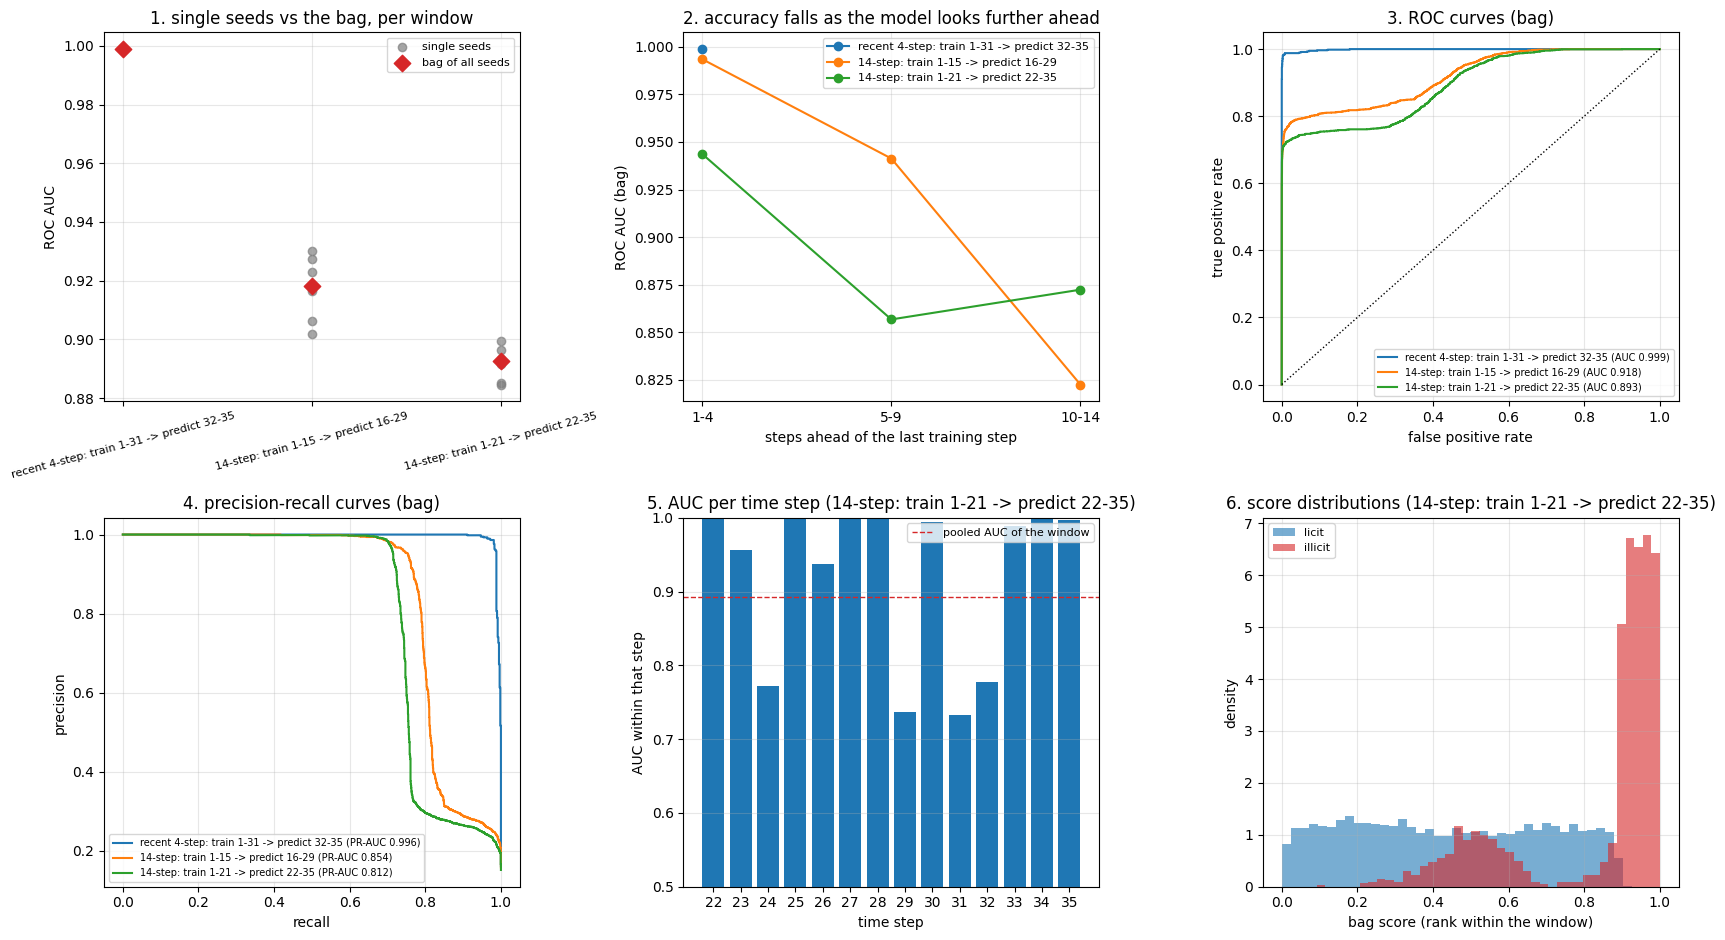

In [ ]:
# Visualisations for above analysis with averaging seeds.

if RUN_VALIDATION:
    colors = plt.cm.tab10.colors
    fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
    names = list(store)

    # (1) AUC per window: every single seed (grey dots) against the bag (red diamond)
    for i, w in enumerate(names):
        d = store[w]
        ax[0, 0].scatter([i] * len(SEEDS), [roc_auc_score(d['y'], d['ranks'][s]) for s in SEEDS], color='tab:gray', alpha=0.7, label='single seeds' if i == 0 else None)
        ax[0, 0].scatter([i], [roc_auc_score(d['y'], d['bag'])], color='tab:red', marker='D', s=70, label='bag of all seeds' if i == 0 else None, zorder=3)
    ax[0, 0].set_xticks(range(len(names))); ax[0, 0].set_xticklabels(names, rotation=15, fontsize=8)
    ax[0, 0].set_ylabel('ROC AUC'); ax[0, 0].set_title('1. single seeds vs the bag, per window'); ax[0, 0].legend(fontsize=8); ax[0, 0].grid(alpha=0.3)

    # (2) AUC by how far ahead each row is (the decay with horizon)
    for i, w in enumerate(names):
        d = store[w]; xs, ys = [], []
        for lo, hi in [(1, 4), (5, 9), (10, 14)]:                          # rows 1-4, 5-9 and 10-14 steps after the last training step
            m = (d['steps'] > d['fit_end'] + lo - 1) & (d['steps'] <= d['fit_end'] + hi)
            if m.sum() and 0 < d['y'][m].sum() < m.sum():
                xs.append(f'{lo}-{hi}'); ys.append(roc_auc_score(d['y'][m], d['bag'][m]))
        ax[0, 1].plot(xs, ys, marker='o', color=colors[i], label=w)
    ax[0, 1].set_xlabel('steps ahead of the last training step'); ax[0, 1].set_ylabel('ROC AUC (bag)')
    ax[0, 1].set_title('2. accuracy falls as the model looks further ahead'); ax[0, 1].legend(fontsize=8); ax[0, 1].grid(alpha=0.3)

    # (3) ROC curves of the bag: true positive rate against false positive rate as the threshold moves
    for i, w in enumerate(names):
        d = store[w]; fpr, tpr, _ = roc_curve(d['y'], d['bag'])
        ax[0, 2].plot(fpr, tpr, color=colors[i], label=f"{w} (AUC {roc_auc_score(d['y'], d['bag']):.3f})")
    ax[0, 2].plot([0, 1], [0, 1], color='k', ls=':', lw=1); ax[0, 2].set_xlabel('false positive rate'); ax[0, 2].set_ylabel('true positive rate')
    ax[0, 2].set_title('3. ROC curves (bag)'); ax[0, 2].legend(fontsize=7); ax[0, 2].grid(alpha=0.3)

    # (4) precision-recall curves of the bag: precision against recall as the threshold moves
    for i, w in enumerate(names):
        d = store[w]; pr, rc, _ = precision_recall_curve(d['y'], d['bag'])
        ax[1, 0].plot(rc, pr, color=colors[i], label=f"{w} (PR-AUC {average_precision_score(d['y'], d['bag']):.3f})")
    ax[1, 0].set_xlabel('recall'); ax[1, 0].set_ylabel('precision'); ax[1, 0].set_title('4. precision-recall curves (bag)'); ax[1, 0].legend(fontsize=7); ax[1, 0].grid(alpha=0.3)

    # (5) AUC of the bag in every single time step of the longest window (which steps break down?)
    wl = [w for w in names if w.startswith('14-step')][-1]; d = store[wl]
    per_step = {t: roc_auc_score(d['y'][d['steps'] == t], d['bag'][d['steps'] == t]) for t in np.unique(d['steps']) if 0 < d['y'][d['steps'] == t].sum() < (d['steps'] == t).sum()}
    ax[1, 1].bar([str(t) for t in per_step], list(per_step.values()), color='tab:blue')
    ax[1, 1].axhline(roc_auc_score(d['y'], d['bag']), color='tab:red', ls='--', lw=1, label='pooled AUC of the window')
    ax[1, 1].set_ylim(min(0.5, min(per_step.values()) - 0.02), 1.0); ax[1, 1].set_xlabel('time step'); ax[1, 1].set_ylabel('AUC within that step')
    ax[1, 1].set_title(f'5. AUC per time step ({wl})'); ax[1, 1].legend(fontsize=8); ax[1, 1].grid(alpha=0.3, axis='y')

    # (6) Compare ensemble score distributions for labelled future validation rows: licit versus illicit.
    ax[1, 2].hist(d['bag'][d['y'] == 0], bins=40, alpha=0.6, color='tab:blue', label='licit', density=True)
    ax[1, 2].hist(d['bag'][d['y'] == 1], bins=40, alpha=0.6, color='tab:red', label='illicit', density=True)
    ax[1, 2].set_xlabel('bag score (rank within the window)'); ax[1, 2].set_ylabel('density'); ax[1, 2].set_title(f'6. score distributions ({wl})'); ax[1, 2].legend(fontsize=8); ax[1, 2].grid(alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print('figures skipped (RUN_VALIDATION = False)')

## 6. Predictions and 2 Final Submissions

In [ ]:
# Final submission generation: fit the enhanced model and write the two competition files.

fit_idx = np.where(is_labeled)[0]
test_idx = np.where(is_test)[0]
test_rank = {}

# These seeds are used for validation and for the final seed ensemble.
SEEDS = [42, 0, 1, 2, 3, 4]

for seed in SEEDS:
    test_rank[seed] = rank(staged_predict(X_final, fit_idx, test_idx, seed)) # use the final enhanced model
    tick(f'final submission seed {seed} done')


def to_submission(values):
    """Return competition-format rows in the same order as test.csv."""
    ranked = pd.DataFrame({
        'txId': nodes['txId'].to_numpy()[test_idx],
        'target': values,
    })
    return test[['index', 'txId']].merge(
        ranked, on='txId', how='left', validate='one_to_one'
    )[['index', 'target']]g


submission_18 = to_submission(test_rank[42])
submission_19 = to_submission(np.mean([test_rank[s] for s in SEEDS], axis=0))

submission_18_path = data_dir / 'submission_18.csv'
submission_19_path = data_dir / 'submission_19.csv'
submission_18.to_csv(submission_18_path, index=False)
submission_19.to_csv(submission_19_path, index=False)
print('written:', submission_18_path)
print('written:', submission_19_path)

[5159.4s] final submission seed 42 done
[5188.9s] final submission seed 0 done
[5219.9s] final submission seed 1 done
[5247.0s] final submission seed 2 done
[5274.3s] final submission seed 3 done
[5301.2s] final submission seed 4 done
written: /Users/varshini/Desktop/nus/nus26/y4s1/fraud analytics/bt4012-bitcoin-fraud-detection2/submission_18.csv
written: /Users/varshini/Desktop/nus/nus26/y4s1/fraud analytics/bt4012-bitcoin-fraud-detection2/submission_19.csv
